# Dar_025 — Phase-conditioned terrain and temperature associations

Environmental EDA supporting Moon base-location comparison with terrain. Existing data only; no mission/equipment policy is adopted.

## Questions

- Q45: How much native thermal-center support survives the image-supported terrain join?
- Q46: Do terrain-temperature rank associations remain after conditioning on solar visibility?
- Q47: What changes after additionally conditioning on the cyclic local-time basis?
- Q48: How do available, positive-spot and fixed-common cohorts change supported associations?
- Q49: Which phase/control fits are undefined, insufficient or rank-deficient?
- Q50: Are conditional associations consistent across common products and regions?

## Input contract, comparisons and limitations

Keep each region and common phase product separate; use the same complete cases for raw versus residual associations. Rank temperature, predictor and solar fraction; retain unranked sine/cosine local-time controls (ranking both cyclic features can make them artificially collinear in a narrow interval). Standardize the design, retain constant/rank-deficient/no-residual statuses, and require 20 complete rows as a predeclared descriptive-fit safeguard, not independent-sample evidence or a mission limit. No causal interpretation, p-values, model training, coefficient transfer or weights.

In [1]:
from pathlib import Path
import sys,json
ROOT=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'outline.md').is_file() and (p/'notebooks').is_dir())
sys.path[:0]=[str(ROOT/'darrel stuff/EDA'),str(ROOT)]
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display,Markdown
from environment_workflow import LocalRun as Run,latest_completed_run
from decision_eda import accepted_input
from site_comparison import cohort_rows
from environmental_selection_eda import candidate_thermal_profiles
from terrain_followup_eda import (SDEM_VARIABLES,terrain_source_statistics,slope_classification_comparison,
    candidate_source_support,illumination_roughness,sample_sdem_products,documented_nominal_bin_size,
    nominal_box_overlap,conditional_rank_relationship)
import terrain_followup_eda as methods
REGION_LIMIT=None  # First execute with 1; None is the complete seven-region scope.
spatial=latest_completed_run(ROOT,'analysis/dar_019_spatial_environment','20261106T175056432784Z_dfd0ab')
candidate=latest_completed_run(ROOT,'analysis/dar_020_candidate_environment','20261106T175311055762Z_b68ce6')
joint=latest_completed_run(ROOT,'analysis/dar_012_joint_environment','20261106T134155791814Z_c6f9ab')
thermal=latest_completed_run(ROOT,'analysis/dar_001_temperature_local_time','20261106T082643415392Z_4e6a0b')
environment=latest_completed_run(ROOT,'analysis/dar_002_temperature_environment','20261106T082929336242Z_623f9f')
sdem=latest_completed_run(ROOT,'lunar_terrain_environment','20261106T180253772848Z_40d3f3')
def regions_in(values):
    regions=sorted(values)
    if REGION_LIMIT is not None:
        if type(REGION_LIMIT) is not int or not 1<=REGION_LIMIT<=len(regions):raise ValueError('Invalid region limit')
        regions=regions[:REGION_LIMIT]
    return regions
def register(run):
    run.input(Path(methods.__file__))
    for name in ['decision_eda.py','moon_p1_analysis.py','site_comparison.py','environmental_selection_eda.py']:
        run.input(ROOT/'darrel stuff/EDA'/name)
def savefig(run,fig,name):
    fig.savefig(run.path(name+'.png'),dpi=120,bbox_inches='tight');display(fig);plt.close(fig)
def publish(run,record):
    run.path('findings.json').write_text(json.dumps(record,indent=2,default=str),encoding='utf-8');display(record)

Accepted local analysis/dar_019_spatial_environment run: 20261106T175056432784Z_dfd0ab
Accepted local analysis/dar_020_candidate_environment run: 20261106T175311055762Z_b68ce6
Accepted local analysis/dar_012_joint_environment run: 20261106T134155791814Z_c6f9ab
Accepted local analysis/dar_001_temperature_local_time run: 20261106T082643415392Z_4e6a0b
Accepted local analysis/dar_002_temperature_environment run: 20261106T082929336242Z_623f9f
Accepted local lunar_terrain_environment run: 20261106T180253772848Z_40d3f3


## Execute the bounded comparison

Completed source runs are pinned and checked. Raw data and older notebooks remain unchanged. Read per-group counts and missingness before interpreting summaries.

Accepted local analysis/dar_017_lunar_site_profiles run: 20261106T163555259282Z_731d59


A3CLR22_10_Leibnitz_Beta_Plateau common-product usable rows 67213


A3CLR22_11_Malapert_Massif common-product usable rows 126846


A3CLR22_12_deGerlache_Kocher_Massif common-product usable rows 79735


A3CLR22_2_Haworth common-product usable rows 224625


A3CLR22_3_Faustini_Rim_A common-product usable rows 78405


A3CLR22_4_deGerlache_Rim_2 common-product usable rows 87356


A3CLR22_5_Connecting_Ridge_Extension common-product usable rows 71699


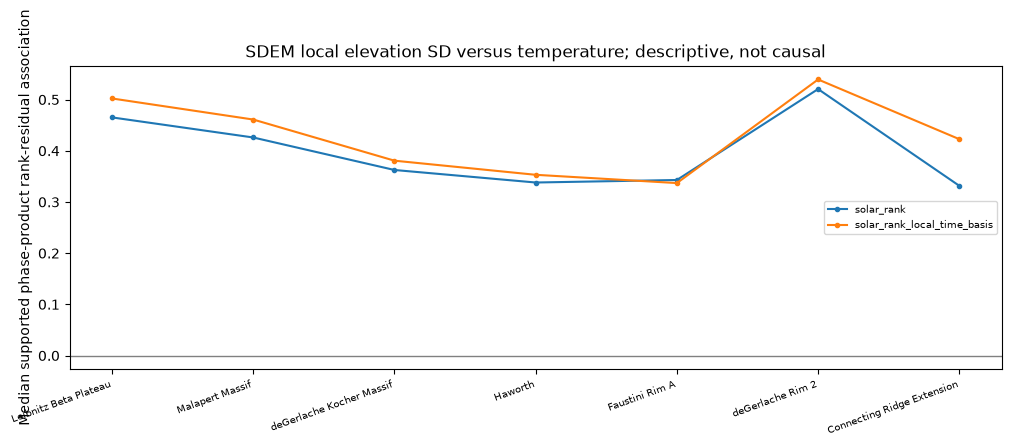

,region,cohort,predictor,control_model,supported_products,minimum_complete_rows,median_same_row_unadjusted_rho,median_partial_rank_rho,minimum_partial_rank_rho,maximum_partial_rank_rho
0,A3CLR22_10_Leibnitz_Beta_Plateau,available,sdem_elevation_m,solar_rank,17,1072,0.254154,-0.022488,-0.553108,0.489821
1,A3CLR22_10_Leibnitz_Beta_Plateau,available,sdem_elevation_m,solar_rank_local_time_basis,17,1072,0.254154,-0.066055,-0.579940,0.511629
2,A3CLR22_10_Leibnitz_Beta_Plateau,available,sdem_local_std_m,solar_rank,17,603,0.040324,0.465182,-0.456541,0.862902
3,A3CLR22_10_Leibnitz_Beta_Plateau,available,sdem_local_std_m,solar_rank_local_time_basis,17,603,0.040324,0.502182,-0.414414,0.848831
4,A3CLR22_10_Leibnitz_Beta_Plateau,available,sdem_slope_deg,solar_rank,17,968,0.154704,0.351432,-0.474386,0.804294
5,A3CLR22_10_Leibnitz_Beta_Plateau,available,sdem_slope_deg,solar_rank_local_time_basis,17,968,0.154704,0.445133,-0.446161,0.780307
18,A3CLR22_11_Malapert_Massif,available,sdem_elevation_m,solar_rank,17,7027,0.045875,-0.124017,-0.579955,0.274361
19,A3CLR22_11_Malapert_Massif,available,sdem_elevation_m,solar_rank_local_time_basis,17,7027,0.045875,-0.179907,-0.547335,0.325386
20,A3CLR22_11_Malapert_Massif,available,sdem_local_std_m,solar_rank,17,5847,0.400480,0.425970,0.111705,0.762086
21,A3CLR22_11_Malapert_Massif,available,sdem_local_std_m,solar_rank_local_time_basis,17,5847,0.400480,0.461024,0.046950,0.748353


{'questions': ['Q45', 'Q46', 'Q47', 'Q48', 'Q49', 'Q50'],
 'regions': 7,
 'comparison_rows': 2142,
 'fit_status_counts': {'descriptive': 1686, 'insufficient_rows': 456},
 'available_phase_summaries': [{'region': 'A3CLR22_10_Leibnitz_Beta_Plateau',
   'cohort': 'available',
   'predictor': 'sdem_elevation_m',
   'control_model': 'solar_rank',
   'supported_products': 17,
   'minimum_complete_rows': 1072,
   'median_same_row_unadjusted_rho': 0.25415380398972637,
   'median_partial_rank_rho': -0.022488216069664904,
   'minimum_partial_rank_rho': -0.5531081620872609,
   'maximum_partial_rank_rho': 0.4898209560104391},
  {'region': 'A3CLR22_10_Leibnitz_Beta_Plateau',
   'cohort': 'available',
   'predictor': 'sdem_elevation_m',
   'control_model': 'solar_rank_local_time_basis',
   'supported_products': 17,
   'minimum_complete_rows': 1072,
   'median_same_row_unadjusted_rho': 0.25415380398972637,
   'median_partial_rank_rho': -0.0660546483269514,
   'minimum_partial_rank_rho': -0.5799400584

In [2]:
CONTROL_MODES={'solar_rank':(['solar_visibility'],[]),
    'solar_rank_local_time_basis':(['solar_visibility','time_sin','time_cos'],['time_sin','time_cos'])}
PREDICTORS=['sdem_slope_deg','sdem_local_std_m','sdem_elevation_m']
with Run(ROOT,'analysis/dar_025_conditional_terrain_thermal',{'region_limit':REGION_LIMIT,
    'sdem_run':str(sdem.relative_to(ROOT)),'environment_run':str(environment.relative_to(ROOT)),
    'minimum_complete_rows':20,'control_modes':CONTROL_MODES,'predictors':PREDICTORS,
    'scope':'same region and common source product; rank response/predictor and solar, unranked cyclic sine/cosine basis',
    'causal_claims':False},'Moon/Thermal/Dar_025_conditional_terrain_temperature.ipynb') as run:
    register(run)
    context=pd.read_csv(accepted_input(run,joint,'native_center_context.csv.gz'))
    footprints=json.loads(accepted_input(run,thermal,'region_footprints.json').read_text())
    profile=latest_completed_run(ROOT,'analysis/dar_017_lunar_site_profiles','20261106T163555259282Z_731d59')
    products=json.loads(accepted_input(run,profile,'comparison_contract.json').read_text())['common_products']
    regions=regions_in(context.region.unique());records=[];source_support=[]
    columns=['region','source_product','clon','clat','local_time_h','tbol','usable','complete_common_cohort','solar_visibility','spot_count']
    for region in regions:
        centers=context.loc[context.region.eq(region),['clon','clat','x_m','y_m']]
        sampled=sample_sdem_products(run,sdem,region,centers,footprints[region]['bounds_m'])
        source_support.append({'region':region,'native_centers':len(sampled),**{key+'_finite_centers':int(sampled[key].notna().sum()) for key in SDEM_VARIABLES}})
        path=accepted_input(run,environment,'paired_observations/'+region+'.csv.gz');pieces=[]
        for chunk in pd.read_csv(path,usecols=columns,chunksize=100_000):
            if not chunk.region.eq(region).all():raise ValueError('Source region mismatch')
            selected=chunk.loc[chunk.source_product.isin(products)]
            if len(selected):pieces.append(selected)
        observations=pd.concat(pieces,ignore_index=True).merge(sampled[['clon','clat',*SDEM_VARIABLES]],on=['clon','clat'],how='left',validate='many_to_one',indicator=True)
        if not observations._merge.eq('both').all():raise ValueError('Native-center SDEM association missing')
        observations=observations.loc[observations.usable].copy()
        if not np.isfinite(observations.tbol).all() or not observations.tbol.gt(0).all() or not observations.local_time_h.between(0,24,inclusive='left').all():raise ValueError('Invalid usable thermal/time values')
        observations['time_sin']=np.sin(observations.local_time_h*np.pi/12)
        observations['time_cos']=np.cos(observations.local_time_h*np.pi/12)
        for cohort in ['available','positive_spots','fixed_common']:
            chosen=cohort_rows(observations,cohort)
            for source in products:
                part=chosen.loc[chosen.source_product.eq(source)]
                for predictor in PREDICTORS:
                    for model,(controls,raw_controls) in CONTROL_MODES.items():
                        result=conditional_rank_relationship(part,predictor,controls,minimum=20,raw_controls=raw_controls)
                        records.append({'region':region,'source_product':source,'cohort':cohort,'predictor':predictor,'control_model':model,**result})
        print(region,'common-product usable rows',len(observations),flush=True)
        del observations,pieces,sampled
    result=pd.DataFrame(records);supported=result.loc[result.status.eq('descriptive')].copy()
    summary=supported.groupby(['region','cohort','predictor','control_model']).agg(supported_products=('source_product','size'),
        minimum_complete_rows=('complete_rows','min'),median_same_row_unadjusted_rho=('unadjusted_rho_same_rows','median'),
        median_partial_rank_rho=('partial_rank_rho','median'),minimum_partial_rank_rho=('partial_rank_rho','min'),
        maximum_partial_rank_rho=('partial_rank_rho','max')).reset_index()
    result.to_csv(run.path('within_product_conditional_rank_relationships.csv'),index=False)
    summary.to_csv(run.path('supported_phase_relationship_summary.csv'),index=False)
    result.groupby(['region','cohort','control_model','status']).size().rename('comparisons').to_csv(run.path('conditional_fit_status_counts.csv'))
    pd.DataFrame(source_support).to_csv(run.path('thermal_center_sdem_support.csv'),index=False)
    p=summary.loc[summary.cohort.eq('available')&summary.predictor.eq('sdem_local_std_m')]
    fig,ax=plt.subplots(figsize=(10,4),layout='constrained')
    for model,group in p.groupby('control_model'):
        q=group.set_index('region').reindex(regions);ax.plot(range(len(regions)),q.median_partial_rank_rho,marker='.',label=model)
    ax.axhline(0,color='grey',lw=1);ax.set_xticks(range(len(regions)),[r.split('_',2)[-1].replace('_',' ') for r in regions],rotation=20,ha='right',fontsize=7)
    ax.set(ylabel='Median supported phase-product rank-residual association',title='SDEM local elevation SD versus temperature; descriptive, not causal');ax.legend(fontsize=7)
    savefig(run,fig,'conditional_roughness_temperature');display(summary.loc[summary.cohort.eq('available')])
    publish(run,{'questions':['Q%02d'%i for i in range(45,51)],'regions':len(regions),'comparison_rows':len(result),
        'fit_status_counts':result.status.value_counts().to_dict(),'available_phase_summaries':summary.loc[summary.cohort.eq('available')].to_dict('records'),
        'limits':['Dependent spatial centers and repeated phase averages; no p-values or independent-trial claim',
        'Rank-residual association with explicit solar/cyclic basis is not a causal effect or prediction',
        'Image-supported SDEM and fixed cohorts select different locations; no universal coefficient or scoring weight inferred']})
OUT=run.directory

## Findings and interpretation

The executed tables, plots and `findings.json` above contain the measured results. Undefined or absent groups are findings, not zero effects. Inspect the declared support/cohort controls rather than selecting whichever result looks most favourable.

## Outputs and next analysis

Generated tables/plots/provenance stay under `darrel stuff/data/processed/analysis/`. See [EDA notes](../../EDA_Notes.md) and [EDA results](../../EDA_Results.md) for status/findings. Proposed algorithm consumption belongs in the [root overview/proposal](../../../Brief_Overview.md#algorithm-proposal), not a duplicated implementation plan here.